# CPE 342 Machine Learning — Assignment 2
### Training models via iterative approach

Model $\;\hat{y} = c_0 + c_1 e^{c_2 x}\;$ fitted by gradient descent on `A2.csv`.

Name: Jakkarin Promsee <br>
ID: 67070501009

---
## 1 · Error / loss function And Gradient of each coefficient

![Task 1](./a2-proff.jpg)


---
## 3 · Update rules

![Task 3](./a2-proff3.jpg)

---
## 4 · Implementation

In [14]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [15]:
# Set matplotlib plot properties

plt.rcParams.update({
    "figure.dpi": 120,
    "font.size": 9,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "grid.linewidth": 0.6,
    "legend.frameon": False,
})

In [16]:
# import data from csv into numpy

df = pd.read_csv("A2.csv")
X, y = df["X"].to_numpy(), df["Y"].to_numpy()
N = len(X)

In [17]:
# verify data
df.describe().T[["count", "min", "max"]]

,count,min,max
X,100.0,0.010773,4.978255
Y,100.0,0.949332,1.970695


In [18]:
# initial learnable variable

c0, c1, c2 = 1.0, 1.0, -1.0   # initial values
alpha = 0.01                  # learning rate
epochs = 5000

loss_history = []

In [19]:
# training

for epoch in range(epochs):
    # model prediction
    y_pred = c0 + c1 * np.exp(c2 * X)

    # loss (MSE)
    error = y_pred - y
    loss = np.mean(error ** 2)
    loss_history.append(loss)

    # gradients
    grad_c0 = (2 / N) * np.sum(error)
    grad_c1 = (2 / N) * np.sum(error * np.exp(c2 * X))
    grad_c2 = (2 / N) * np.sum(error * c1 * X * np.exp(c2 * X))

    # simultaneous update
    c0 -= alpha * grad_c0
    c1 -= alpha * grad_c1
    c2 -= alpha * grad_c2

    # print loss
    if epoch in [0, 5, 10, 100, 500] or epoch % 1000 == 0:
        print(f"epoch: {epoch:4d} | loss: {loss:.6f}")

epoch:    0 | loss: 0.006012
epoch:    5 | loss: 0.005395
epoch:   10 | loss: 0.004896
epoch:  100 | loss: 0.002726
epoch:  500 | loss: 0.002195
epoch: 1000 | loss: 0.001893
epoch: 2000 | loss: 0.001588
epoch: 3000 | loss: 0.001398
epoch: 4000 | loss: 0.001260


---
## 5 · Loss over iterations & resulting coefficients

In [20]:
# print final result

print(f"c0 = {c0: .4f}")
print(f"c1 = {c1: .4f}")
print(f"c2 = {c2: .4f}")
print()
print(f"initial loss = {loss_history[0]:.6f}")
print(f"final   loss = {loss_history[-1]:.6f}")

c0 =  0.9872
c1 =  0.9408
c2 = -1.2469

initial loss = 0.006012
final   loss = 0.001156


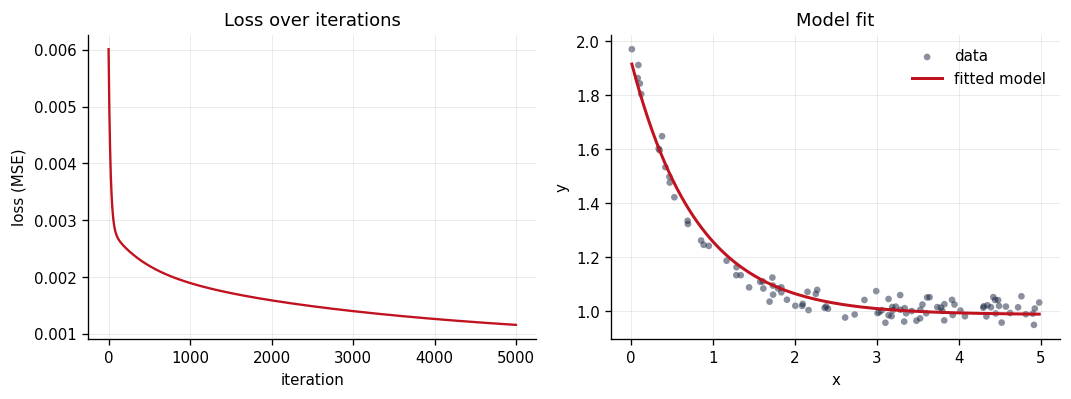

In [21]:
# ploting

fig, ax = plt.subplots(1, 2, figsize=(9, 3.4))

ax[0].plot(loss_history, lw=1.4, color="#c1121f")
ax[0].set(xlabel="iteration", ylabel="loss (MSE)", title="Loss over iterations")

xs = np.linspace(X.min(), X.max(), 200)
ax[1].scatter(X, y, s=16, color="#14213d", alpha=0.5, edgecolor="none", label="data")
ax[1].plot(xs, c0 + c1 * np.exp(c2 * xs), color="#c1121f", lw=1.8, label="fitted model")
ax[1].set(xlabel="x", ylabel="y", title="Model fit")
ax[1].legend()

fig.tight_layout()
plt.show()